In [1]:
import numpy as np
import pymc as pm  # if using pymc >=4
import arviz as az
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns

import pandas as pd

import json

from pytensor.tensor import cumsum
import pytensor.tensor as at

import os
from glob import glob

import mvEEG.mvEEG as mvEEG

In [ ]:
OVERWRITE_MODELS = False
DESCRIPTION = "signedDprime"  # description for saving outputs, either "signedDprime" or "signedCorrWhite"
if DESCRIPTION == "signedCorrWhite":
    RESCALE = 1e6  # rescaling factor for RDMs to improve numerical stability in Bayesian models
else:
    RESCALE = 1  # if not rescaling, then set to 1 (i.e., no rescaling)

In [3]:
DROP_SS0 = True

In [4]:
code_dict = {
    "A0": 10,
    "A1": 11,
    "A2": 12,
    "A3": 13,
    "A4": 14,
    "A6": 16,
    "A8": 18,
    "M0": 20,
    "M1": 21,
    "M2": 22,
    "M3": 23,
    "M4": 24,
    "M6": 26,
    "M8": 28,
}
conditions = list(code_dict.keys())

if DROP_SS0:
    conditions.remove("A0")
    conditions.remove("M0")

ridx, cidx = np.triu_indices(len(conditions), k=1)

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 1100
)  # time window to average distances over, only includes when probes could appear

In [5]:
with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['19', '32', '33']

In [6]:
f = open("k_estimates.json")
k_res = json.load(f)
k_df = pd.DataFrame(pd.DataFrame(k_res).loc[["4", "6", "8"]].mean())  # average across SS4-8
k_df = k_df[~k_df.index.isin(rejected_subs)]  # remove rejected subjects
k_df["high_k"] = k_df[0] > k_df[0].quantile()
k_df["contrast"] = k_df.index.map(lambda sub: 0.5 if k_df.loc[sub, "high_k"] else -0.5)

sub_contrast_vec = k_df["contrast"].values
sub_group_vec = k_df["high_k"].astype(int).values

k_df

,0,high_k,contrast
01,4.900391,True,0.5
02,3.748426,True,0.5
03,2.386335,False,-0.5
04,1.732817,False,-0.5
05,1.558493,False,-0.5
06,2.497469,False,-0.5
07,3.577476,False,-0.5
08,3.021303,False,-0.5
09,4.457212,True,0.5
10,1.594584,False,-0.5


In [7]:
sub_contrast_vec, sub_group_vec

(array([ 0.5,  0.5, -0.5, -0.5, -0.5, -0.5, -0.5, -0.5,  0.5, -0.5, -0.5,
         0.5, -0.5,  0.5,  0.5,  0.5,  0.5,  0.5,  0.5,  0.5,  0.5,  0.5,
        -0.5, -0.5, -0.5, -0.5, -0.5, -0.5,  0.5,  0.5]),
 array([1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 1, 1]))

In [8]:
# TODO: use bids to manage data paths
rdm_files = sorted(glob(f"../data/derivatives/*/RDMs/*desc-{DESCRIPTION}*npy"))
rdm_files = [f for f in rdm_files if f.split("-")[1].split("/")[0] not in rejected_subs]
rdm_files

['../data/derivatives/sub-01/RDMs/sub-01_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-02/RDMs/sub-02_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-03/RDMs/sub-03_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-04/RDMs/sub-04_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-05/RDMs/sub-05_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-06/RDMs/sub-06_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-07/RDMs/sub-07_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-08/RDMs/sub-08_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-09/RDMs/sub-09_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-10/RDMs/sub-10_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-11/RDMs/sub-11_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-12/RDMs/sub-12_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/deriva

In [9]:
# Number of Items in WM
WM_setsizes = np.array([int(cond[1]) if (cond[0] == "M") else 0 for cond in conditions])
WMss_options = sorted(np.unique(WM_setsizes))
WM_setsize_map = {ss: i for i, ss in enumerate(WMss_options)}
cond_WMss_idx = np.array([WM_setsize_map[ss] for ss in WM_setsizes])

# Number of attended areas, assuming that people can filter our distractors
condition_ATTN = np.array([int(cond[1]) for cond in conditions])
ATTNss_options = sorted(np.unique(condition_ATTN))
ATTN_setsize_map = {ss: i for i, ss in enumerate(ATTNss_options)}
cond_ATTNss_idx = np.array([ATTN_setsize_map[ss] for ss in condition_ATTN])


q = np.array(
    [
        cond_WMss_idx[ridx],
        cond_WMss_idx[cidx],
        cond_ATTNss_idx[ridx],
        cond_ATTNss_idx[cidx],
    ]
).T

In [10]:
cond_WMss_idx, cond_ATTNss_idx

(array([0, 0, 0, 0, 0, 0, 1, 2, 3, 4, 5, 6]),
 array([0, 1, 2, 3, 4, 5, 0, 1, 2, 3, 4, 5]))

<Axes: >

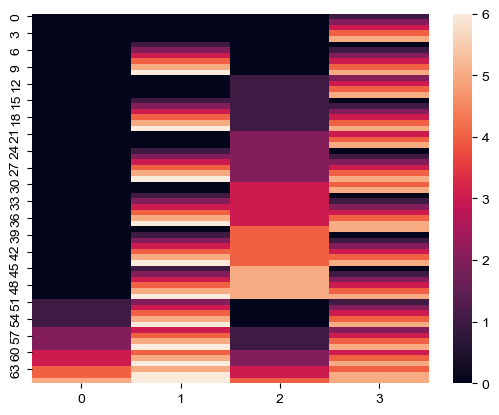

In [11]:
sns.heatmap(q)

# load in and average the RDMs for display

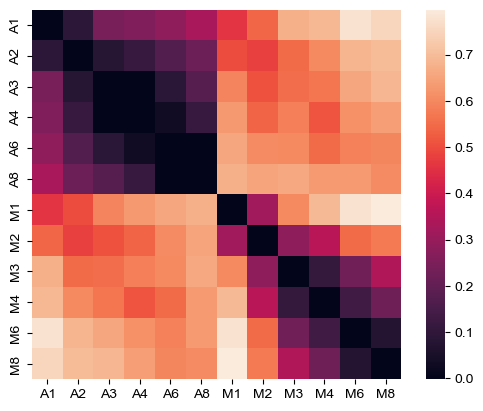

In [12]:
group_rdm = np.zeros((len(conditions), len(conditions)))
for i, f in enumerate(rdm_files):
    sub_id = f.split("-")[1].split("/")[0]
    sub_rdms = np.load(f)
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)
    group_rdm += sub_rdm_delay
group_rdm /= len(rdm_files)
_ = sns.heatmap(group_rdm, xticklabels=conditions, yticklabels=conditions, square=True)
plt.savefig(f"figures/group_rdm_{DESCRIPTION}.png", transparent=True, bbox_inches="tight")

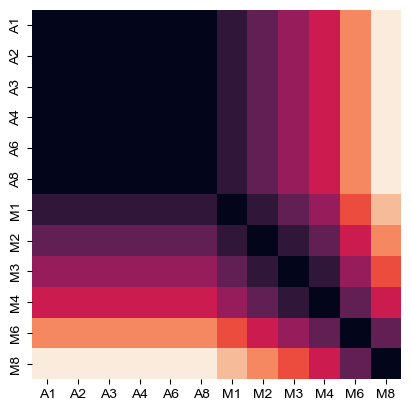

In [13]:
_ = sns.heatmap(
    np.abs(WM_setsizes[:, np.newaxis] - WM_setsizes[np.newaxis, :]),
    xticklabels=conditions,
    yticklabels=conditions,
    cbar=False,
    square=True,
)
plt.savefig(f"../figures/WM_setsize_rdm.png", transparent=True, bbox_inches="tight")

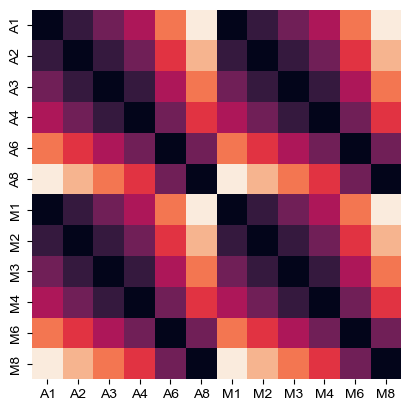

In [14]:
_ = sns.heatmap(
    np.abs(condition_ATTN[:, np.newaxis] - condition_ATTN[np.newaxis, :]),
    xticklabels=conditions,
    yticklabels=conditions,
    cbar=False,
    square=True,
)
plt.savefig(f"../figures/ATTN_setsize_rdm.png", transparent=True, bbox_inches="tight")

# MODEL DEFINITION

In [15]:
def build_model(d, q):
    """
    Build a model to estimate the WM and spatial attention functions with the following assumptions:
    1. The WM function is a guassian random walk, **is the same with or without placeholders**
    2. The spatial attention function is monotonic, **and is the same with or without placeholders**
    3. The stimulus energy function is monotonic

    **s indicate assumptions specific to this model

    Arguments
    ---------
    d : array of shape (n_distances,)
        The vectorized distances in upper (or lower) triangle of RDM
    q : array of shape (n_distances, n_regressors)
        Condition indices
    For this model the following column structure is expected:
    0. WM set size at first condition
    1. WM set size at second condition
    2. Spatial attention set size at first condition
    3. Spatial attention set size at second condition
    4. unique subject index for each distance (i.e., same for all distances from the same subject)

    """
    N = len(d)
    wmK = np.unique(q[:, :2]).size  # number of WM set sizes
    attnK = np.unique(q[:, 2:4]).size  # number of attended areas
    nsub = np.unique(q[:, 4]).size  # number of subjects

    # check that the quad indices are in the expected format
    assert np.min(q) == 0
    assert q.shape[0] == N
    assert (np.max(q[:, :2]) + 1) == wmK
    assert (np.max(q[:, 2:4]) + 1) == attnK

    # steps between conditions we'd like to fit to data
    coords = {
        "innovations_num_WM": np.arange(1, wmK),
        "innovations_num_Attn": np.arange(1, attnK),
        "subject": np.arange(0, nsub),
        "trial_num": np.arange(1, N + 1),
    }

    with pm.Model(coords=coords) as model:

        # prior on noise in RDM values, used in likelihood below
        RDM_sigma_pop = pm.Exponential("RDM_sigma_pop", lam=5)  # OLD lam=10
        RDM_sigma_subs = pm.Exponential("RDM_sigma_subs", lam=1 / RDM_sigma_pop, dims=("subject",))

        # ~~~~~~~~~~~~ 1. Working Memory ~~~~~~~~~~~~

        # WM prior on changes between successive levels in underlying function
        # assumes gaussian process, with random step between levels
        # population-level walk
        # scale_innov_WM = pm.Exponential("scale_innov_WM", lam=1)  # scale of innovations before exp transform

        # # group-level function
        # log_mu_WM = pm.GaussianRandomWalk(
        #     "log_mu_WM_minus_first",
        #     mu=0,
        #     sigma=1,
        #     init_dist=pm.Normal.dist(0, 1),
        #     dims=("innovations_num_WM",),
        # )
        # mu_WM = pm.Deterministic("mu_WM", pm.math.exp(scale_innov_WM * log_mu_WM))  # convert to positives, scale

        mu_WM = pm.TruncatedNormal(
            "mu_WM", mu=0.5, sigma=0.25, lower=0, dims=("innovations_num_WM",)
        )  # population-level function values at each set size (except first, which is fixed to 0)

        # keep track of innovations for savage dickey model comparison
        mu_WM_innovs = pm.Deterministic("mu_WM_innovs", mu_WM[1:] - mu_WM[:-1])

        sigma_lvls_prior_WM = pm.Exponential(
            "sigma_lvls_hyperprior_WM", lam=4
        )  # prior on variability of the subjects at each set size - setting it broad to include very small values
        sigma_lvls_WM = pm.Exponential("sigma_lvls_WM", scale=sigma_lvls_prior_WM, dims=("innovations_num_WM",))

        sub_vals_WM = pm.TruncatedNormal(
            "sub_vals_WM_minus_first",
            mu=mu_WM,
            sigma=sigma_lvls_WM,
            lower=0,
            dims=("subject", "innovations_num_WM"),
        )
        sub_vals_WM = pm.Deterministic("sub_vals_WM", at.concatenate((np.zeros((nsub, 1)), sub_vals_WM), axis=1))

        # ~~~~~~~~~~~~ 2. Spatial Attention ~~~~~~~~~~~~
        # define the population-level dirichlet prior
        pop_dir_Attn = pm.Dirichlet("pop_dir_Attn", a=np.ones(attnK - 1), dims=("innovations_num_Attn",))
        pop_dir_scale_Attn = pm.Exponential(
            "pop_dir_scale_Attn", lam=5
        )  # scale of dirichlet concentration, higher = less variance
        pop_concentration_Attn = pop_dir_scale_Attn * pop_dir_Attn

        # each subject's dirichlet is drawn from a scaled version of the population dirichlet
        sub_dir_Attn = pm.Dirichlet(
            "sub_dir_Attn",
            a=pop_concentration_Attn,
            dims=("subject", "innovations_num_Attn"),
        )
        sub_mu_Attn = pm.Deterministic("sub_mu_Attn_minus_first", cumsum(sub_dir_Attn, axis=1))
        sub_mu_Attn = pm.Deterministic("sub_mu_Attn", at.concatenate((np.zeros((nsub, 1)), sub_mu_Attn), axis=1))

        # subject scale is also hierarchical
        pop_scale_Attn = pm.Exponential("pop_scale_Attn", lam=5)
        sub_scale_Attn = pm.Exponential("sub_scale_Attn", lam=1 / pop_scale_Attn, dims=("subject",))

        # save the population function as a deterministic variable for later examination
        pop_mu_Attn = pm.Deterministic("pop_mu_Attn", pop_scale_Attn * cumsum(pop_dir_Attn, axis=0))

        # ~~~~~~~~~~~~ 3. Combine into full model ~~~~~~~~~~~~

        # start by getting difference scores between pairs of conds based on WM, Attn, and StimEnergy levels
        # WM
        mu_i_WM = sub_vals_WM[q[:, 4].astype(int), q[:, 0].astype(int)]
        mu_j_WM = sub_vals_WM[q[:, 4].astype(int), q[:, 1].astype(int)]
        mu_delta_WM = pm.math.abs(mu_i_WM - mu_j_WM)

        # NOTE: attn is flipped axes (subject, levels) compared to WM
        # Attn
        mu_i_Attn = sub_mu_Attn[q[:, 4].astype(int), q[:, 2].astype(int)]
        mu_j_Attn = sub_mu_Attn[q[:, 4].astype(int), q[:, 3].astype(int)]
        mu_delta_Attn = pm.math.abs(mu_i_Attn - mu_j_Attn) * sub_scale_Attn[q[:, 4].astype(int)]

        # likelihood function
        dist_est = mu_delta_WM + mu_delta_Attn
        pm.Normal("d", mu=dist_est, sigma=RDM_sigma_subs[q[:, 4].astype(int)], observed=d, dims=("trial_num",))

    return model

In [16]:
# build up distances and inputs

for i, f in enumerate(rdm_files):
    sub_id = f.split("-")[1].split("/")[0]
    sub_rdms = np.load(f)
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)

    sub_dists = sub_rdm_delay[ridx, cidx] * RESCALE  # vectorize upper triangle, rescale for numerical stability

    sub_q = np.concatenate(
        [
            q,
            # np.array([[k_df.loc[sub_id, "high_k"]] * q.shape[0]]).T,  # add column to differentiate k groups
            np.array([[i] * q.shape[0]]).T,  # add column to index subjects
        ],
        axis=1,
    )

    if i == 0:
        pop_dists = sub_dists
        pop_q = sub_q
    else:
        pop_dists = np.concatenate((pop_dists, sub_dists))
        pop_q = np.concatenate((pop_q, sub_q), axis=0)

print(pop_dists.shape, pop_q.shape)

(1980,) (1980, 5)


# Prior checks

In [17]:
model = build_model(pop_dists, pop_q)

with model:
    prior = pm.sample_prior_predictive(20_000)

Sampling: [RDM_sigma_pop, RDM_sigma_subs, d, mu_WM, pop_dir_Attn, pop_dir_scale_Attn, pop_scale_Attn, sigma_lvls_WM, sigma_lvls_hyperprior_WM, sub_dir_Attn, sub_scale_Attn, sub_vals_WM_minus_first]


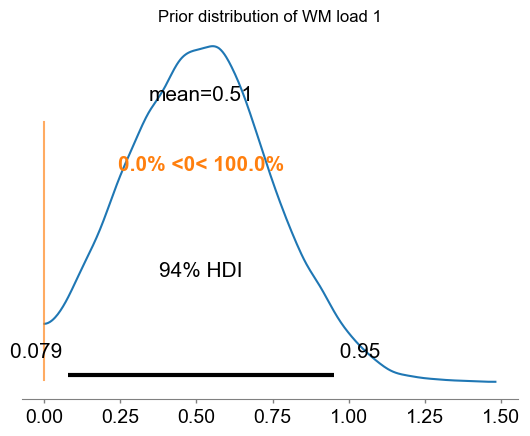

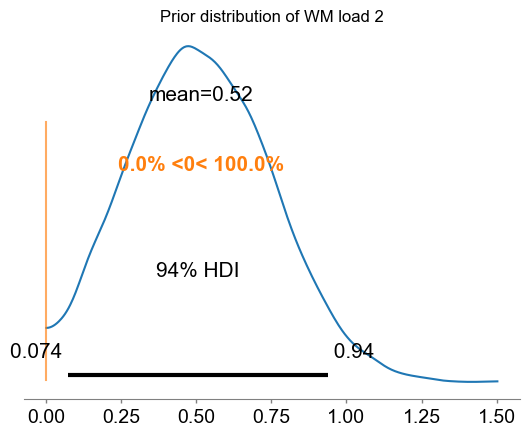

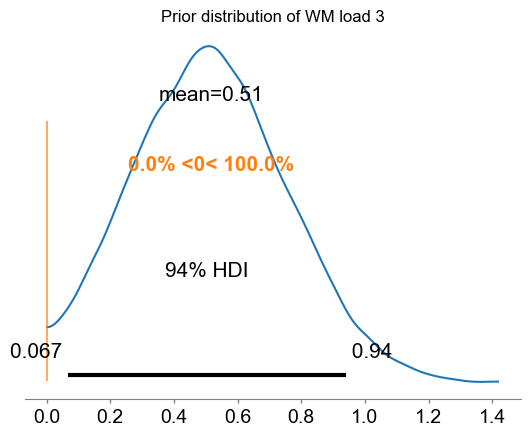

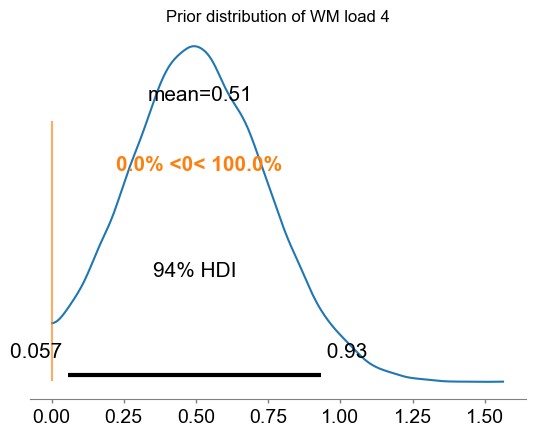

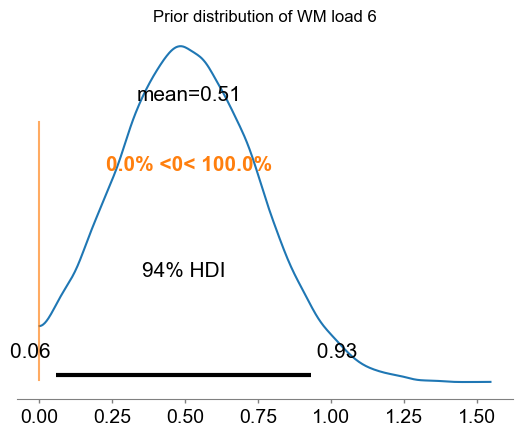

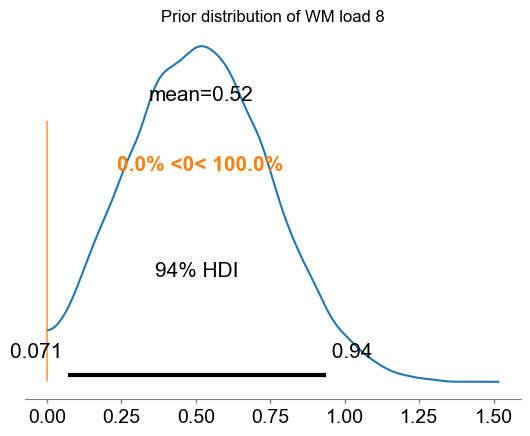

In [18]:
mu_WMs = np.squeeze(prior.prior["mu_WM"].values).T

set_sizes = [1, 2, 3, 4, 6, 8]
for i in range(mu_WMs.shape[0]):
    az.plot_posterior(mu_WMs[i], ref_val=0)
    plt.title(f"Prior distribution of WM load {set_sizes[i]}")
    plt.show()
    plt.close()

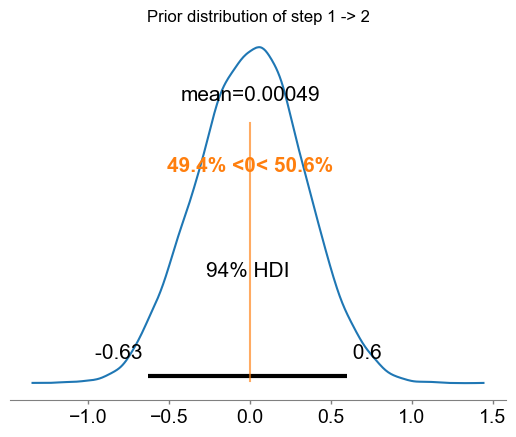

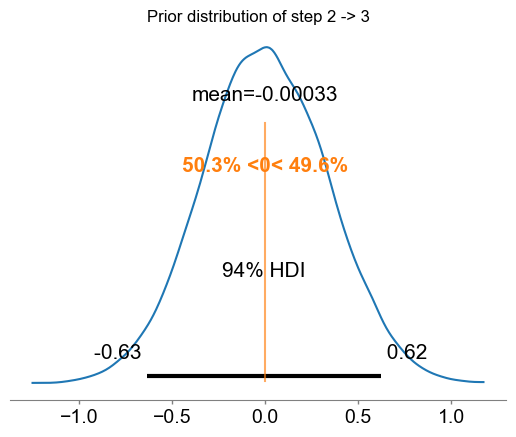

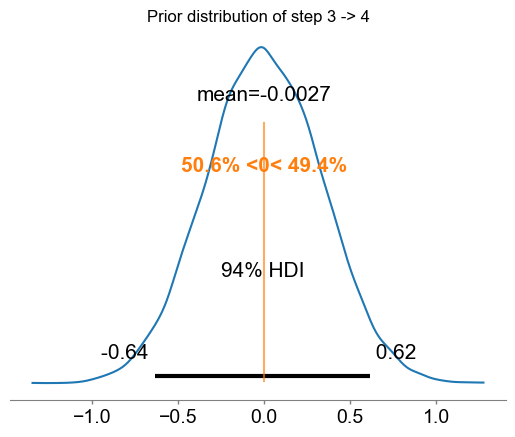

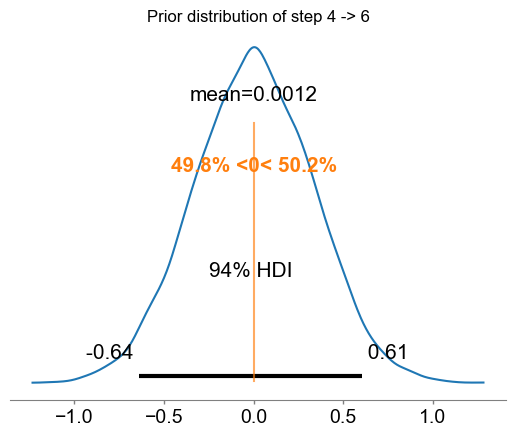

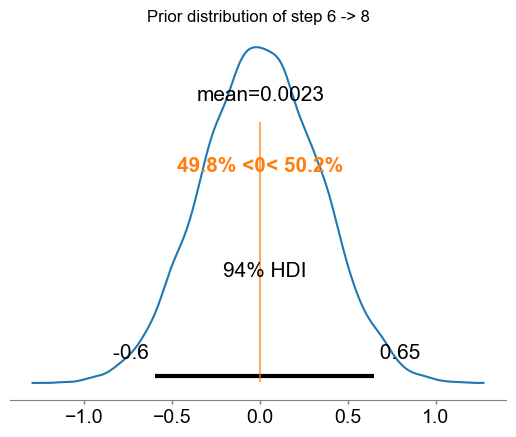

In [19]:
# priors
# 0,1,2,3,4,6,8
# get the adjacent differences between the WM levels
step_diffs = np.squeeze(prior.prior["mu_WM_innovs"].values).T

set_sizes = [1, 2, 3, 4, 6, 8]
for i in range(step_diffs.shape[0]):
    az.plot_posterior(step_diffs[i], ref_val=0)
    plt.title(f"Prior distribution of step {set_sizes[i]} -> {set_sizes[i+1]}")
    plt.show()
    plt.close()

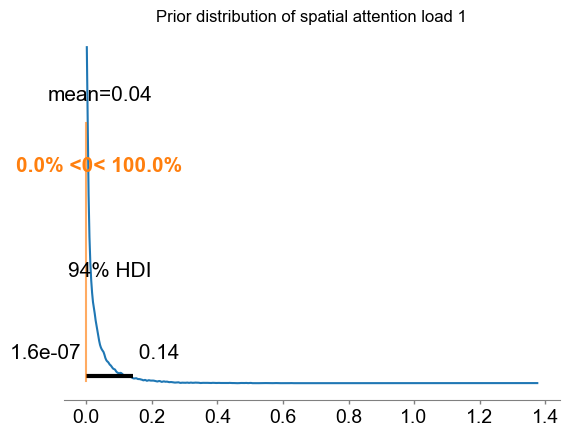

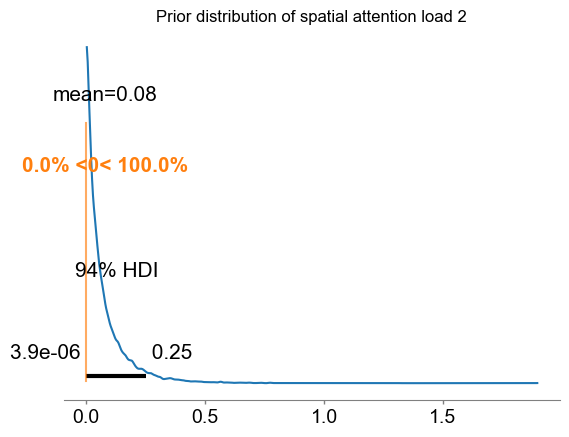

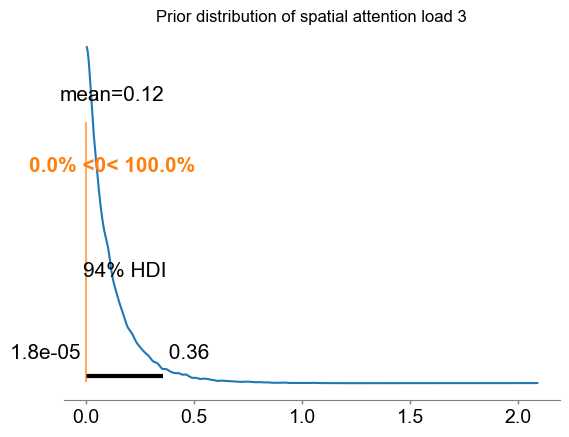

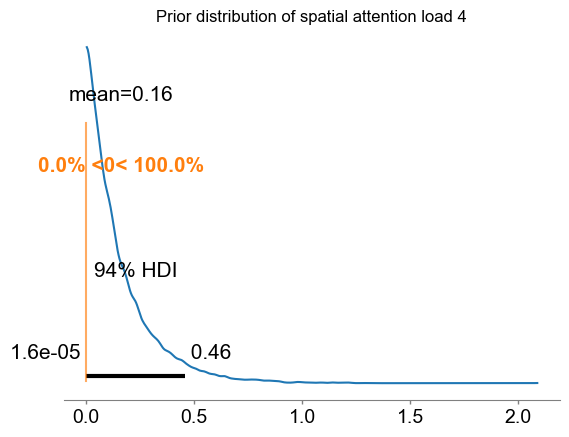

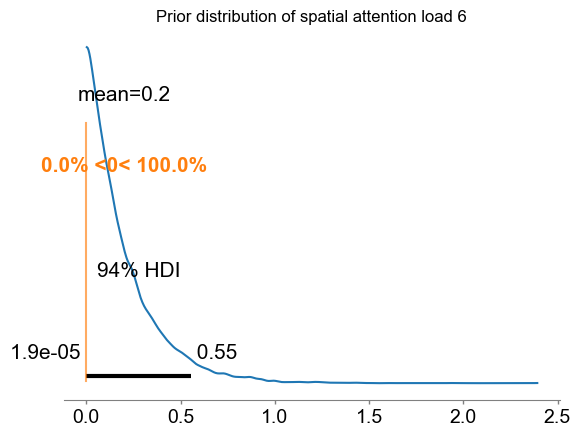

In [20]:
mu_attn = np.squeeze(prior.prior["pop_mu_Attn"].values).T
attn_set_sizes = [1, 2, 3, 4, 6, 8]
for i in range(mu_attn.shape[0]):
    az.plot_posterior(mu_attn[i], ref_val=0)
    plt.title(f"Prior distribution of spatial attention load {attn_set_sizes[i]}")
    plt.show()
    plt.close()

# Fit Model

In [21]:
# fit model
model_path = f"models/{DESCRIPTION}_model"
if (not os.path.exists(model_path)) or OVERWRITE_MODELS:
    model = build_model(pop_dists, pop_q)

    with model:
        trace = pm.sample(
            10_000,  # real samples per chain
            tune=10_000,  # warmup samples per chain
            chains=4,
            target_accept=0.9999,
            random_seed=42,
            return_inferencedata=True,
            nuts_sampler="numpyro",
        )
        trace.to_netcdf(model_path)
else:
    trace = az.from_netcdf(model_path)

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 0/20000 [00:00<?, ?it/s]

In [22]:
# check the effective sample size
summary_table = az.summary(trace)
summary_table

/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:592: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_s

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
RDM_sigma_pop,0.166,0.031,0.113,0.226,0.0,0.0,68484.0,28482.0,1.0
RDM_sigma_subs[0],0.191,0.018,0.159,0.226,0.0,0.0,48868.0,27967.0,1.0
RDM_sigma_subs[1],0.140,0.014,0.116,0.167,0.0,0.0,40007.0,27780.0,1.0
RDM_sigma_subs[2],0.146,0.014,0.120,0.174,0.0,0.0,38409.0,26407.0,1.0
RDM_sigma_subs[3],0.259,0.025,0.214,0.305,0.0,0.0,39030.0,26034.0,1.0
...,...,...,...,...,...,...,...,...,...
pop_mu_Attn[0],0.138,0.031,0.085,0.197,0.0,0.0,44444.0,29665.0,1.0
pop_mu_Attn[1],0.229,0.045,0.148,0.314,0.0,0.0,41870.0,27497.0,1.0
pop_mu_Attn[2],0.277,0.053,0.183,0.377,0.0,0.0,48607.0,28011.0,1.0
pop_mu_Attn[3],0.332,0.062,0.223,0.448,0.0,0.0,56279.0,27786.0,1.0


In [23]:
summary_table.loc[summary_table.r_hat > 1.01]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [24]:
summary_table.r_hat.describe()

count    901.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: r_hat, dtype: float64

In [25]:
summary_table.loc[summary_table.r_hat == 1.01]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat


In [26]:
mini_summary = az.summary(trace, var_names=["mu_WM", "pop_dir_Attn", "pop_dir_scale_Attn"])
mini_summary.ess_bulk.describe()

count       12.000000
mean     18526.500000
std      13245.712284
min       3216.000000
25%       4602.000000
50%      18972.000000
75%      29085.000000
max      41349.000000
Name: ess_bulk, dtype: float64

2918.0


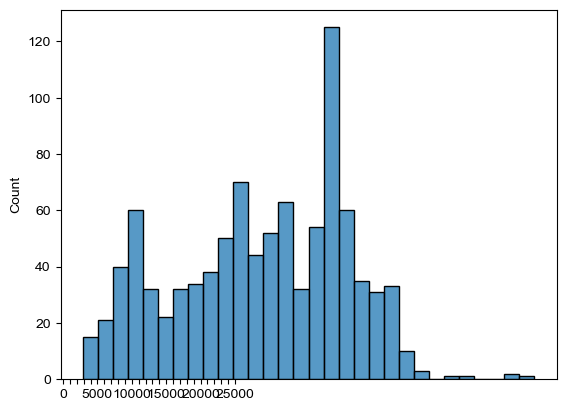

In [27]:
_ = sns.histplot(summary_table.ess_bulk.values, bins=30)
# only add xtick labels every 5000
_ = plt.xticks(range(0, 26000, 1000), labels=[str(x) if x % 5000 == 0 else "" for x in range(0, 26000, 1000)])

print(summary_table.ess_bulk.min())

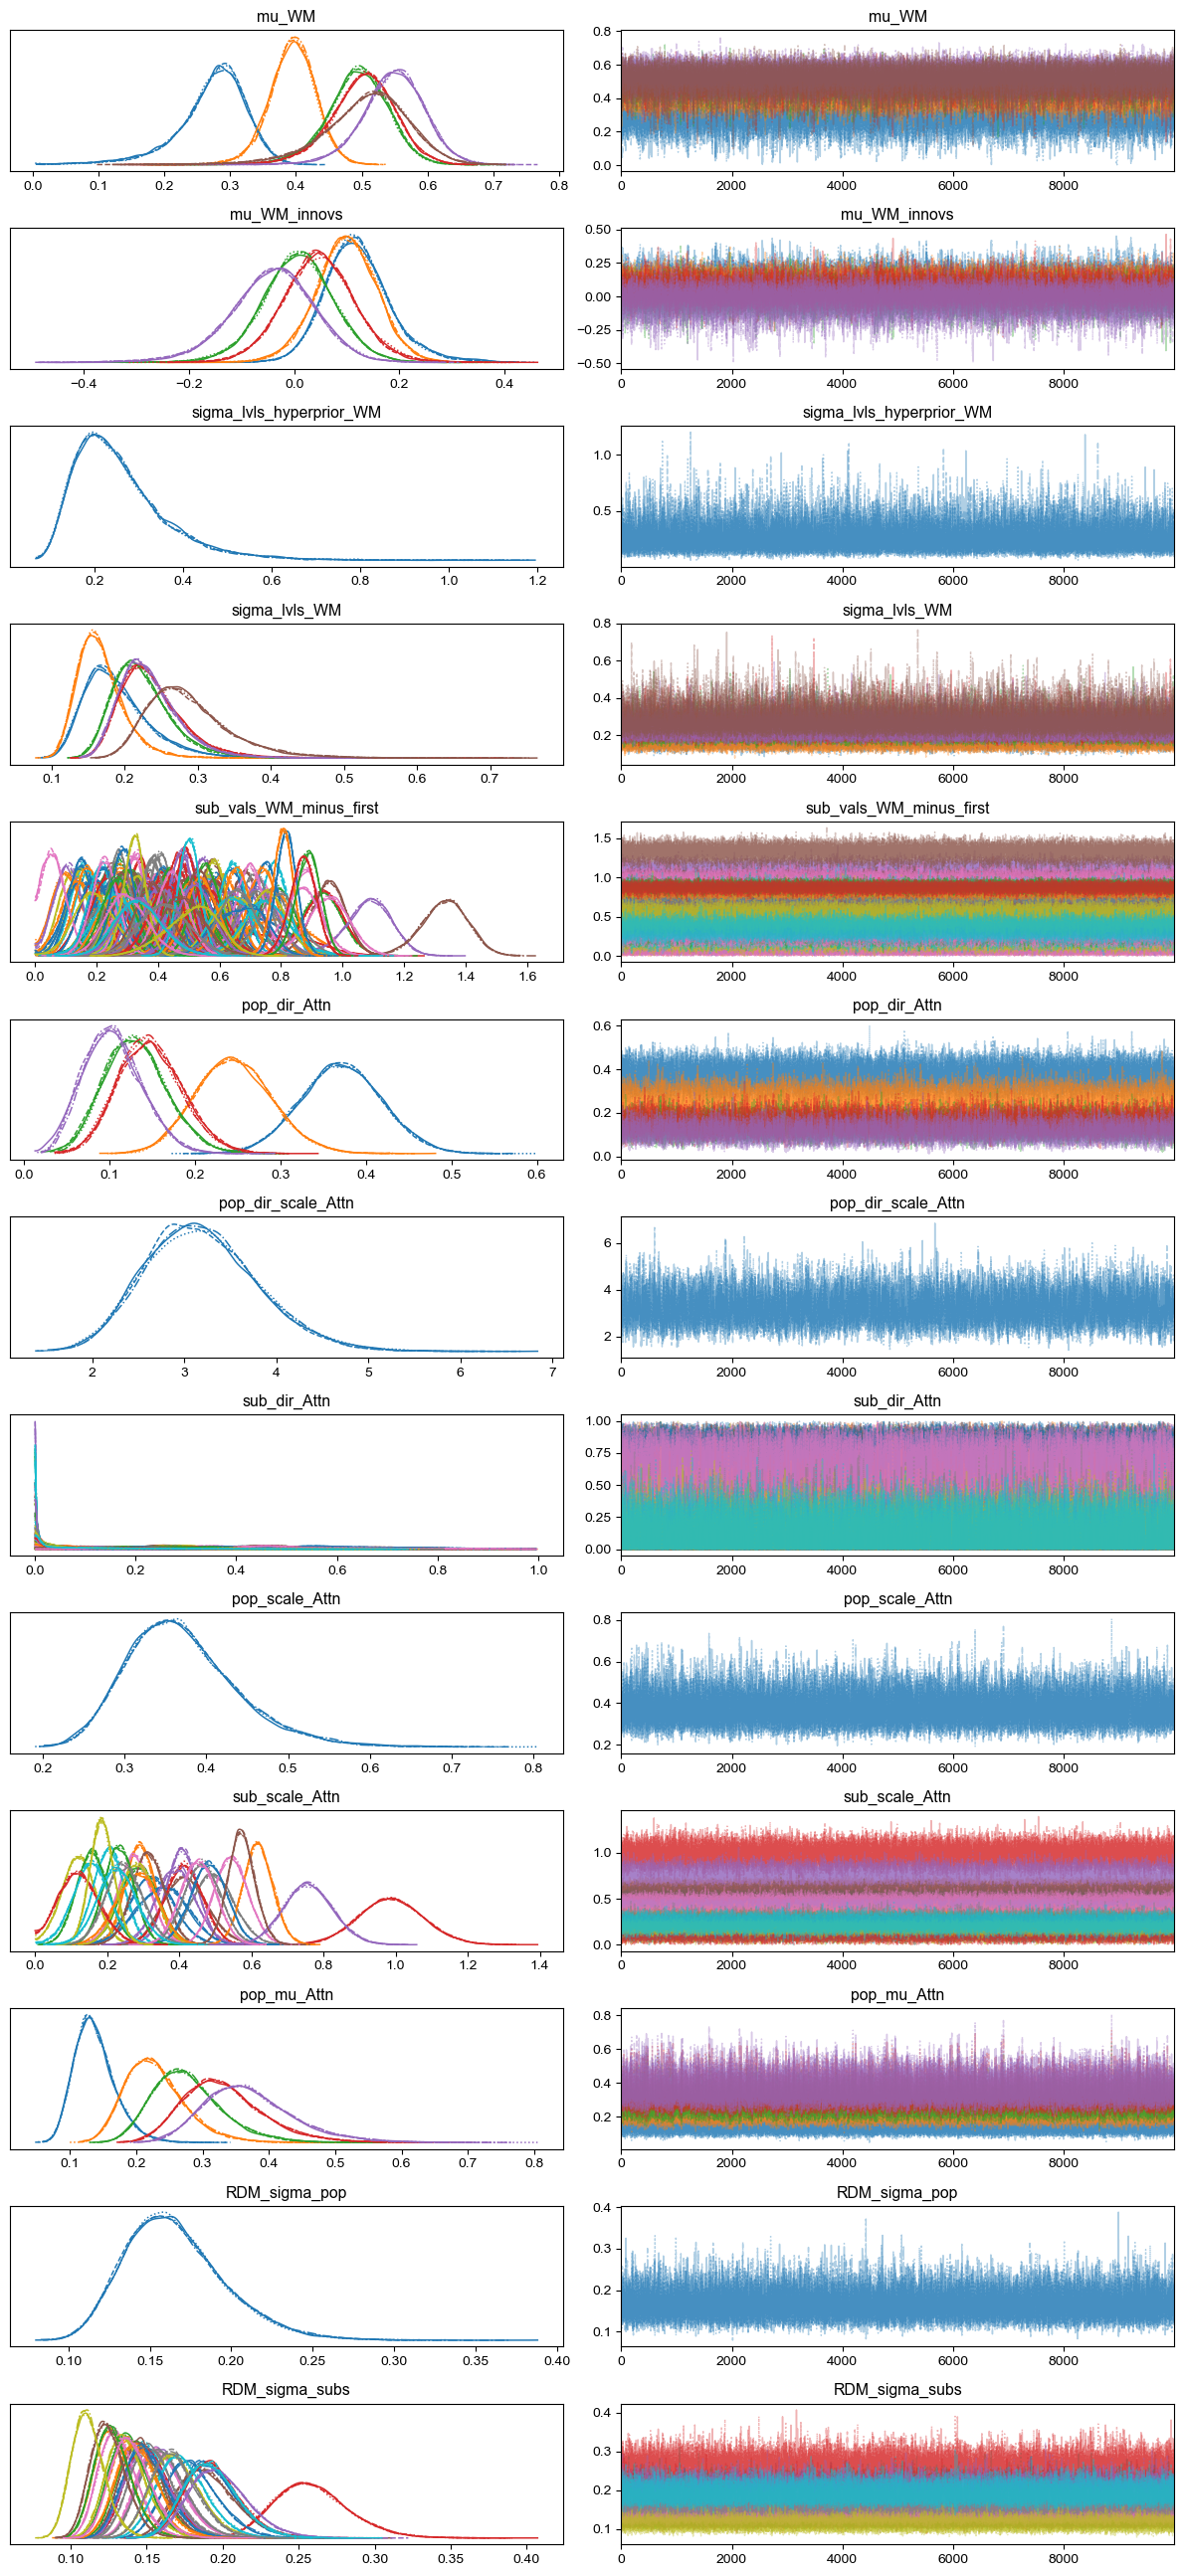

In [35]:
_ = pm.plot_trace(
    trace,
    var_names=[
        "mu_WM",
        "mu_WM_innovs",
        "sigma_lvls_hyperprior_WM",
        "sigma_lvls_WM",
        "sub_vals_WM_minus_first",
        "pop_dir_Attn",
        "pop_dir_scale_Attn",
        "sub_dir_Attn",
        # "sub_mu_Attn_minus_first",
        "pop_scale_Attn",
        "sub_scale_Attn",
        "pop_mu_Attn",
        "RDM_sigma_pop",
        "RDM_sigma_subs",
    ],
)
plt.tight_layout()
plt.show()
plt.close()

# Pretty plots

In [36]:
hdi_prob = 0.94

trc = trace.posterior.stack(draws=("chain", "draw"))

param_xs = {"mu_WM": [0, 1, 2, 3, 4, 6, 8], "mu_Attn": [1, 2, 3, 4, 6, 8]}
condition_indices = {"mu_WM": cond_WMss_idx, "mu_Attn": cond_ATTNss_idx}

param_xlabels = {
    "mu_WM": "WM Set Size [0=Spatial Attention Task]",
    "mu_Attn": "# Attended Locations",
}

param_colors = {"mu_WM": "red", "mu_Attn": "blue"}

param_titles = {
    "mu_WM": "Working Memory Load Function",
    "mu_Attn": "Spatial Attention Load Function",
}

In [37]:
def plot_param(param, param_vals):
    # assumes param_vals is (n_param_levels, n_samples)
    lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
    upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]

    ax = sns.lineplot(x=param_xs[param], y=param_vals.mean(1), color="dark" + param_colors[param], linewidth=2)
    plt.fill_between(param_xs[param], lower, upper, alpha=0.4, color="dark" + param_colors[param])

    # plt.ylim(-0.01, 0.7)
    plt.yticks(np.round(plt.yticks()[0], 1))
    # plt.ylim(-0.01, 0.7)

    plt.xticks(param_xs[param])
    plt.xlabel(param_xlabels[param])

    plt.ylabel("Neural Distance (d') from Baseline")
    plt.title(param_titles[param])
    sns.despine()
    plt.savefig(f"figures/{param}_pop.svg")
    plt.savefig(f"figures/{param}_pop.png", dpi=300)
    plt.show()
    plt.close()

    mean_vals = param_vals.mean(1)
    condition_vals = mean_vals[condition_indices[param]]
    sns.heatmap(
        np.abs(condition_vals[:, np.newaxis] - condition_vals[np.newaxis, :]),
        xticklabels=conditions,
        yticklabels=conditions,
        square=True,
    )
    plt.savefig(f"figures/expected_rdm_{param}.png", transparent=True, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_param_k_diffs(param, sub_vals):
    # assumes sub_vals is (n_subjects, n_param_levels, n_samples)

    # divide into subjects into groups and mean across subs within each group
    sub_vals_high_k = sub_vals[k_df.high_k.values, :, :].mean(0)
    sub_vals_low_k = sub_vals[~k_df.high_k.values, :, :].mean(0)
    sub_vals_diff = sub_vals_high_k - sub_vals_low_k

    high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
    low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
    diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)

    ax = sns.lineplot(
        x=param_xs[param],
        y=sub_vals_high_k.mean(1),
        label="High K Subjects",
        color="dark" + param_colors[param],
        linewidth=2,
    )
    plt.fill_between(param_xs[param], high_K_hdi[:, 0], high_K_hdi[:, 1], alpha=0.4, color="dark" + param_colors[param])

    sns.lineplot(
        x=param_xs[param],
        y=sub_vals_low_k.mean(1),
        label="Low K Subjects",
        color=param_colors[param],
        ax=ax,
        linewidth=2,
    )
    plt.fill_between(param_xs[param], low_k_hdi[:, 0], low_k_hdi[:, 1], alpha=0.4, color=param_colors[param])

    sns.lineplot(x=param_xs[param], y=sub_vals_diff.mean(1), label="High K - Low K", color="black", ax=ax, linewidth=2)
    plt.fill_between(param_xs[param], diff_hdi[:, 0], diff_hdi[:, 1], alpha=0.4, color="black")

    plt.hlines(0, param_xs[param][0], param_xs[param][-1], linestyle="--", color="gray", zorder=-1)

    plt.xticks(param_xs[param])
    plt.xlabel(param_xlabels[param])
    # plt.ylim(-0.05, 0.7)
    plt.yticks(np.round(plt.yticks()[0], 1))
    # plt.ylim(-0.05, 0.7)
    plt.ylabel("Neural Distance (d') from Baseline")
    plt.legend(loc="upper left")
    plt.title(param_titles[param])
    sns.despine()
    plt.savefig(f"figures/{param}_split_half.svg")
    plt.savefig(f"figures/{param}_split_half.png", dpi=300)
    plt.show()
    plt.close()

In [38]:
def plot_individual_subjects(param, sub_vals, color_by_k=False):
    # assumes sub_vals is (n_subjects, n_param_levels, n_samples)
    ncols = 6
    n_rows = int(np.ceil(sub_vals.shape[0] / ncols))
    fig, axes = plt.subplots(n_rows, ncols, figsize=(12, 4 * n_rows), sharex=True, sharey=True)
    axes = [axes] if sub_vals.shape[0] == 1 else axes.flatten()

    for i in range(sub_vals.shape[0]):
        if color_by_k:
            color = "red" if k_df.loc[k_df.index[i], "high_k"] else "blue"
        else:
            color = "gray"
        sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
        ax = sns.lineplot(x=param_xs[param], y=sub_vals[i].mean(1), color=color, alpha=0.5, ax=axes[i])
        ax.fill_between(param_xs[param], sub_hdi[:, 0], sub_hdi[:, 1], alpha=0.2, color=color)

    plt.xticks(param_xs[param])
    plt.xlabel(param_xlabels[param])
    # plt.ylim(-0.01, 1.5)
    plt.yticks(np.round(plt.yticks()[0], 1))
    # plt.ylim(-0.01, 1.5)
    plt.ylabel("Neural Distance (d') from Baseline")
    sns.despine()
    plt.savefig(f"figures/{param}_individual_subs.svg")
    plt.savefig(f"figures/{param}_individual_subs.png", dpi=300)
    plt.show()
    plt.close()

# WM

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:3: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:4: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]


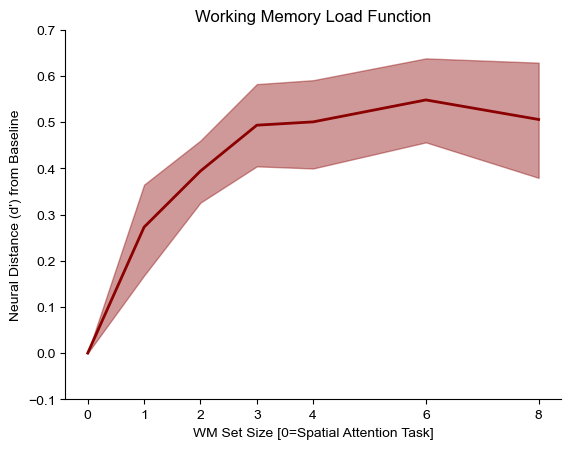

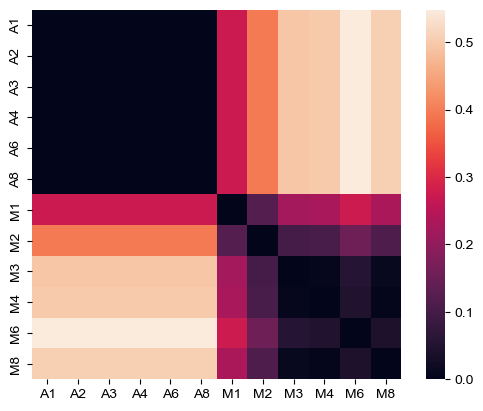

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:45: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:46: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:47: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)


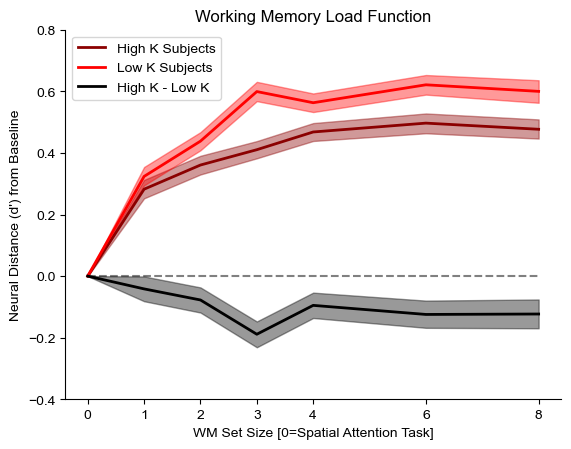

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets

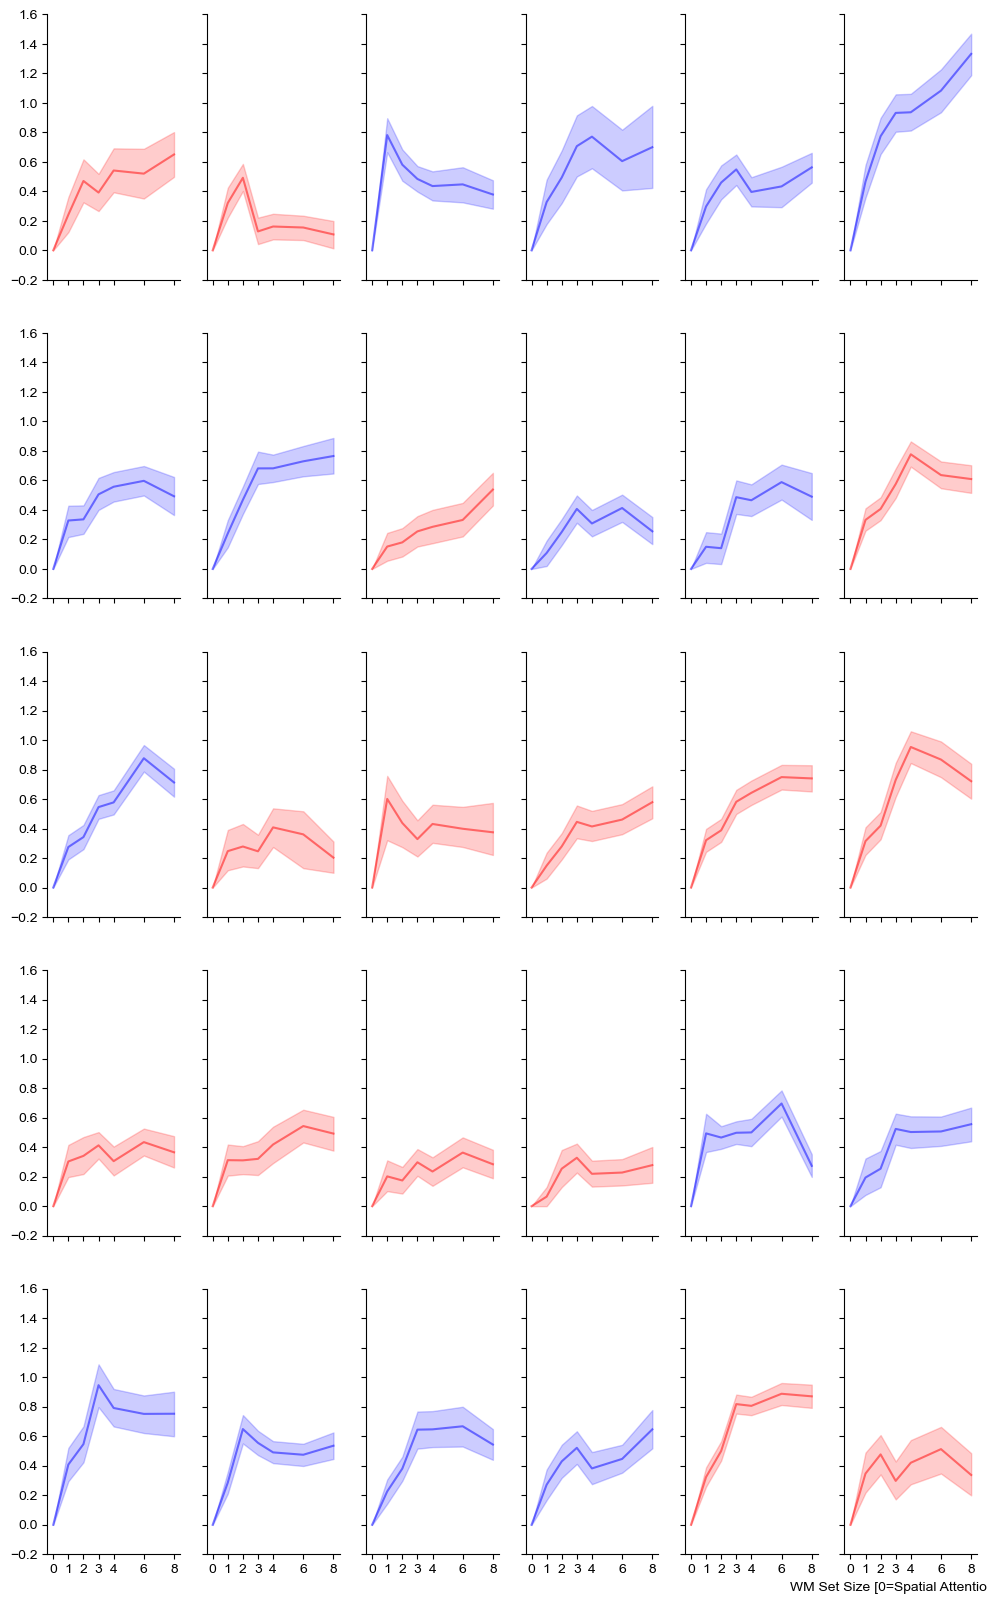

In [39]:
mu_WM_vals = trc["mu_WM"].values

mu_WM_vals = np.concatenate((np.zeros((1, mu_WM_vals.shape[1])), mu_WM_vals), axis=0)  # add 0 for set size 0

plot_param("mu_WM", mu_WM_vals)

mu_WM_sub = trc["sub_vals_WM"].values
plot_param_k_diffs("mu_WM", mu_WM_sub)

plot_individual_subjects("mu_WM", mu_WM_sub, color_by_k=True)

# Spatial Attention

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:3: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:4: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(param_vals.T, hdi_prob=hdi_prob)[:, 1]


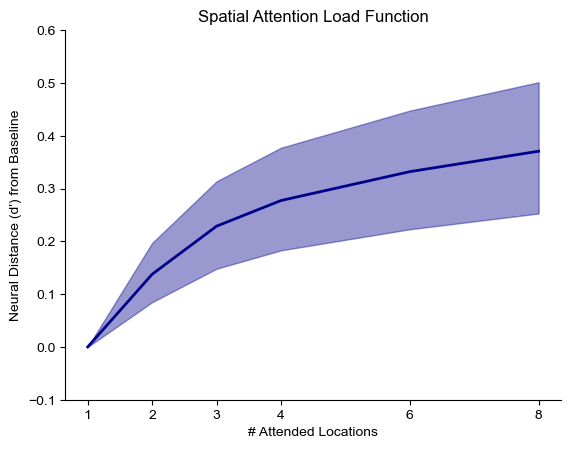

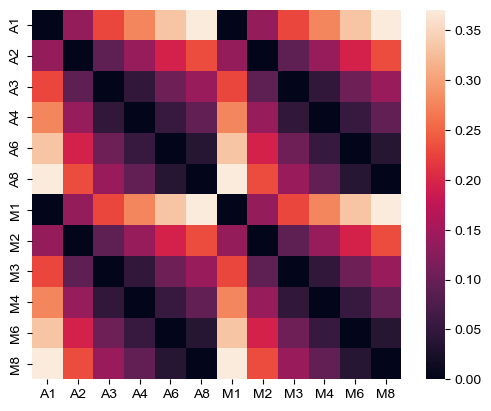

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:45: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  high_K_hdi = az.hdi(sub_vals_high_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:46: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  low_k_hdi = az.hdi(sub_vals_low_k.T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/1153785811.py:47: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  diff_hdi = az.hdi(sub_vals_diff.T, hdi_prob=hdi_prob)


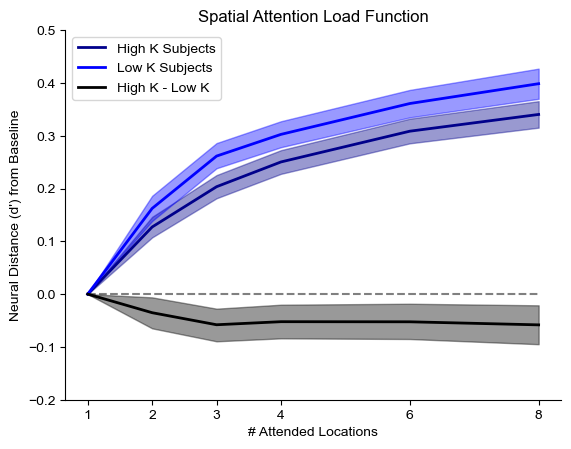

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  sub_hdi = az.hdi(sub_vals[i].T, hdi_prob=hdi_prob)
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_96250/465876471.py:13: FutureWarning: hdi currently interprets

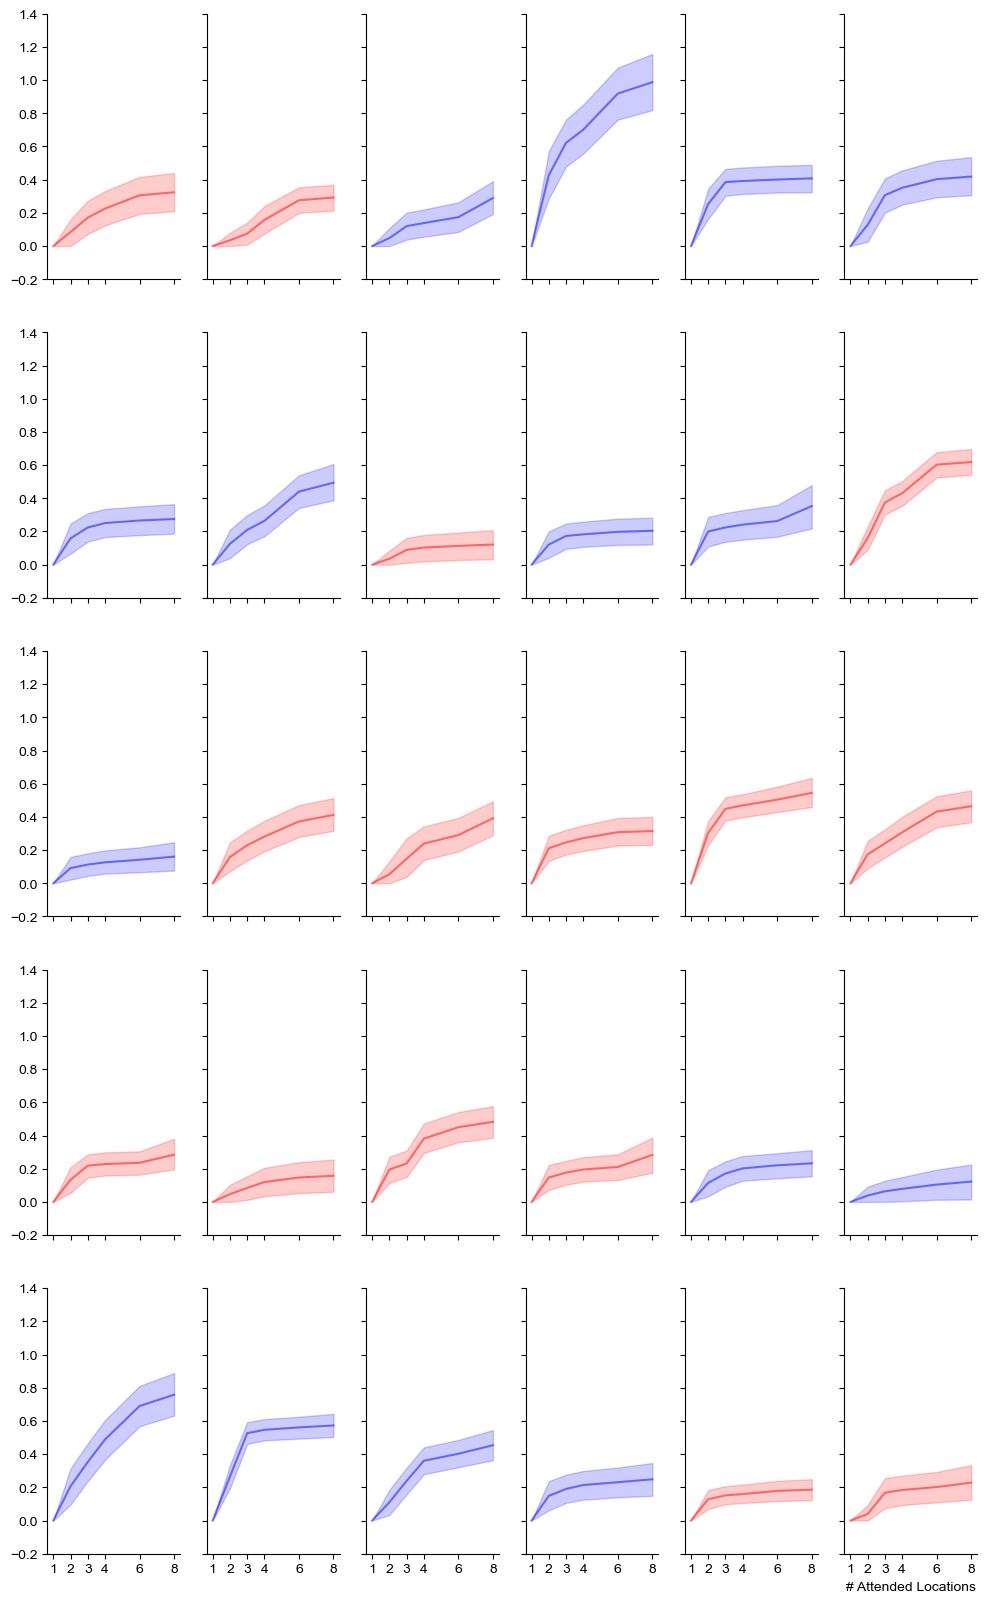

In [33]:
sub_mu_Attn = trc["sub_mu_Attn"].values
sub_scale_Attn = trc["sub_scale_Attn"].values
sub_mu_Attn = sub_mu_Attn * sub_scale_Attn[:, np.newaxis, :]  # scale by subject scale

pop_mu_Attn = trc["pop_mu_Attn"].values
pop_mu_Attn = np.concatenate((np.zeros((1, pop_mu_Attn.shape[1])), pop_mu_Attn), axis=0)  # add 0 for set size 1

plot_param("mu_Attn", pop_mu_Attn)

plot_param_k_diffs("mu_Attn", sub_mu_Attn)

plot_individual_subjects("mu_Attn", sub_mu_Attn, color_by_k=True)